In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import c, k, e
from scipy.signal import correlate

from optic.comm.modulation import modulateGray
from optic.dsp.core import lowPassFIR, firFilter, upsample
from optic.models.devices import mzm
from optic.plot import eyediagram
from optic.utils import parameters, dBm2W

In [16]:
#Khai báo bộ đối tượng tham số
param = parameters() 
# Tham số tín hiệu & Thời gian
param.Rs = 10e9          # Tốc độ ký hiệu: 10 GBaud (10 Gbps với OOK)
param.SpS = 16           # Số mẫu trên 1 ký hiệu (Samples per symbol)
param.Fs = param.Rs * param.SpS  # Tần số lấy mẫu (160 GHz)
param.Nbits = 2**14      # Tổng số bit mô phỏng (16,384 bits)

# Tham số Bộ điều chế Quang MZM (Khối phát)
param.Vpi = 2.0          # Điện áp Vpi = 2V
param.Vb = -1.0          # Điện áp Bias = -1V
P_tx_dBm = 0             # Công suất quang phát: 0 dBm
P_tx_W = dBm2W(P_tx_dBm) # Công suất phát quy đổi sang Watt (1e-3 W)

# Tham số Kênh truyền Sợi quang (Fiber Channel)
param.L = 20            # Chiều dài sợi quang: L km
param.alpha = 0.2        # Hệ số suy hao: 0.2 dB/km
param.D = 16.0           # Hệ số tán sắc sắc thể: 16 ps/nm/km
param.lamda = 1550e-9    # Bước sóng hoạt động: 1550 nm

# Tham số Bộ thu Quang Photodiode & Nhiễu (Receiver)
param.R = 0.85           # Độ đáp ứng quang (Responsivity) = 0.85 A/W
param.B = 0.75 * param.Rs # Băng thông bộ thu = 7.5 GHz
T_temp = 300             # Nhiệt độ môi trường = 300 K
R_load = 50              # Trở kháng tải = 50 Ohm


--------------------------------------------------
1. KẾT QUẢ SỐ LIỆU TÍNH TOÁN KHỐI PHÁT (TRANSMITTER)
--------------------------------------------------
• Công suất quang phát đỉnh (Peak Tx Power): 0.691 mW
• Công suất quang phát trung bình:           0.501 mW (-3.00 dBm)


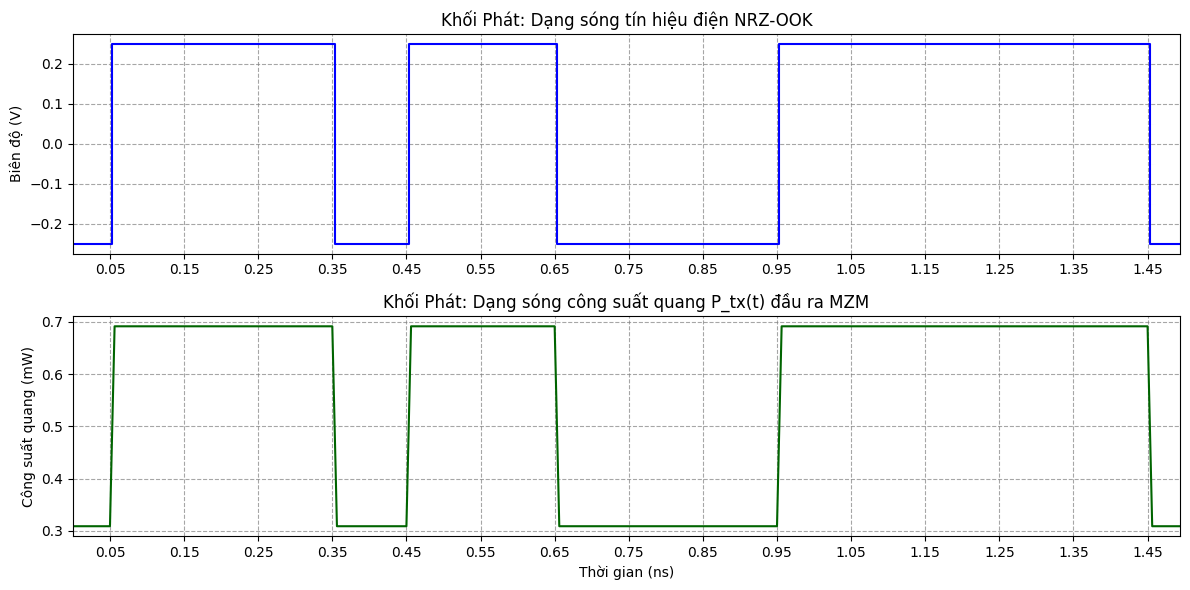

In [17]:
# QUÁ TRÌNH XỬ LÝ KHỐI PHÁT 
# 1. Tạo chuỗi bit ngẫu nhiên
bitsTx = np.random.randint(0, 2, param.Nbits)

# 2. Điều chế chuỗi bit thành dạng sóng điện NRZ
symbTx = modulateGray(bitsTx, 2, 'pam')
symbUp = upsample(symbTx, param.SpS)
p = np.ones(param.SpS) / np.sqrt(param.SpS)
sigTx_elec = firFilter(p, symbUp)

# 3. Mã hóa tín hiệu điện sang dạng sóng quang qua MZM
Ai = np.sqrt(P_tx_W)
E_tx = mzm(Ai, sigTx_elec, param)

# TÍNH TOÁN SỐ LIỆU KHỐI PHÁT 
P_tx_optical = np.abs(E_tx)**2
P_tx_avg = np.mean(P_tx_optical)
P_tx_avg_dBm = 10 * np.log10(P_tx_avg / 1e-3)

print("\n--------------------------------------------------")
print("1. KẾT QUẢ SỐ LIỆU TÍNH TOÁN KHỐI PHÁT (TRANSMITTER)")
print("--------------------------------------------------")
print(f"• Công suất quang phát đỉnh (Peak Tx Power): {np.max(P_tx_optical)*1e3:.3f} mW")
print(f"• Công suất quang phát trung bình:           {P_tx_avg*1e3:.3f} mW ({P_tx_avg_dBm:.2f} dBm)")

# VẼ ĐỒ THỊ DẠNG SÓNG KHỐI PHÁT
fig, ax = plt.subplots(2, 1, figsize=(12, 6))
N_simulate = 15 * param.SpS
t_ns = np.arange(N_simulate) / param.Fs * 1e9
Tb_ns = (1 / param.Rs) * 1e9  
bit_ticks = np.arange(0.05, t_ns[-1] + Tb_ns/2, Tb_ns)

ax[0].step(t_ns, sigTx_elec[:N_simulate], color='blue', where='mid')
ax[0].set_title("Khối Phát: Dạng sóng tín hiệu điện NRZ-OOK")
ax[0].set_ylabel("Biên độ (V)")

ax[1].plot(t_ns, P_tx_optical[:N_simulate]*1e3, color='darkgreen')
ax[1].set_title("Khối Phát: Dạng sóng công suất quang P_tx(t) đầu ra MZM")
ax[1].set_xlabel("Thời gian (ns)")
ax[1].set_ylabel("Công suất quang (mW)")

for a in ax:
    a.set_xticks(bit_ticks)
    a.set_xlim([0, t_ns[-1]])
    a.grid(True, which='both', linestyle='--', alpha=0.7, color='gray')
plt.tight_layout()
plt.show()


--------------------------------------------------
2. KẾT QUẢ SỐ LIỆU KÊNH TRUYỀN SỢI QUANG (FIBER CHANNEL)
--------------------------------------------------
• Suy hao tổng của cự ly 20 km:             4.00 dB
• Công suất quang thu được tại cuối sợi:    0.1994 mW (-7.00 dBm)
• Trường quang cực đại:                     0.018
• Công suất quang thu đỉnh (Peak Rx Power): 0.325 mW


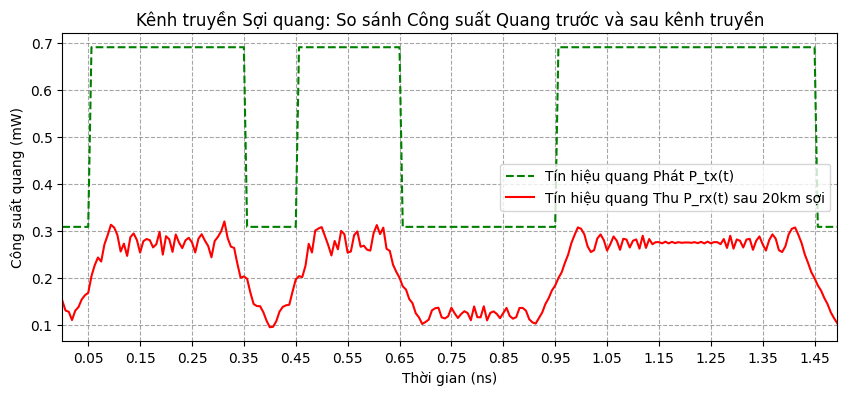

In [18]:
# QUÁ TRÌNH XỬ LÝ KÊNH TRUYỀN SỢI QUANG
# 1. Tính toán tham số vật lý của sợi quang
alpha_m = param.alpha / (10 * np.log10(np.e) * 1e3) # Chuyển dB/km sang 1/m
beta2 = -(param.lamda**2 / (2 * np.pi * c)) * (param.D * 1e-6) # s^2/m
Total_Loss_dB = param.alpha * param.L

# 2. Truyền tín hiệu quang trong miền tần số (Tán sắc & Suy hao)
N_samples = len(E_tx)
freq = np.fft.fftfreq(N_samples, 1/param.Fs)
omega = 2 * np.pi * freq
H_fiber = np.exp(-alpha_m * (param.L * 1e3) / 2) * np.exp(+1j * (beta2 / 2) * (omega**2) * (param.L * 1e3))
E_rx_optical = np.fft.ifft(np.fft.fft(E_tx) * H_fiber)

#TÍNH TOÁN SỐ LIỆU KÊNH TRUYỀN 
P_rx_optical = np.abs(E_rx_optical)**2
P_rx_avg = np.mean(P_rx_optical)
P_rx_avg_dBm = 10 * np.log10(P_rx_avg / 1e-3)

print("\n--------------------------------------------------")
print("2. KẾT QUẢ SỐ LIỆU KÊNH TRUYỀN SỢI QUANG (FIBER CHANNEL)")
print("--------------------------------------------------")
print(f"• Suy hao tổng của cự ly {param.L} km:             {Total_Loss_dB:.2f} dB")
print(f"• Công suất quang thu được tại cuối sợi:    {P_rx_avg*1e3:.4f} mW ({P_rx_avg_dBm:.2f} dBm)")
#print(f"• Trường quang cực đại:                     {np.max(E_rx_optical):.3f}")
print(f"• Trường quang cực đại:                     {np.max(np.abs(E_rx_optical)):.3f}")
print(f"• Công suất quang thu đỉnh (Peak Rx Power): {np.max(P_rx_optical)*1e3:.3f} mW")

#VẼ ĐỒ THỊ SO SÁNH KÊNH TRUYỀN
Tb_ns = (1 / param.Rs) * 1e9  
bit_ticks = np.arange(0.05, t_ns[-1] + Tb_ns/2, Tb_ns)
plt.figure(figsize=(10, 4))
plt.plot(t_ns, P_tx_optical[:N_simulate]*1e3, label='Tín hiệu quang Phát P_tx(t)', color='green', linestyle='--')
plt.plot(t_ns, P_rx_optical[:N_simulate]*1e3, label=f'Tín hiệu quang Thu P_rx(t) sau {param.L}km sợi', color='red')
plt.title("Kênh truyền Sợi quang: So sánh Công suất Quang trước và sau kênh truyền")
plt.xlabel("Thời gian (ns)")
plt.ylabel("Công suất quang (mW)")
plt.legend()

for a in plt.gcf().axes:
    a.set_xticks(bit_ticks)
    a.set_xlim([0, t_ns[-1]])
    a.grid(True, which='both', linestyle='--', alpha=0.7, color='gray')
    
plt.show()

In [19]:
# TÍNH CHIỀU DÀI SUY HAO VÀ CHIỀU DÀI TÁN SẮC
# 1. Chiều dài suy hao L_alpha
alpha_km = param.alpha / (10 * np.log10(np.e))  # 1/km
L_alpha = 1 / alpha_km                          # km

# 2. Chiều dài tán sắc L_D
T0 = 1 / param.Rs                               # thời lượng 1 bit (s)
L_disp_m = (T0**2) / np.abs(beta2)              # m
L_disp_km = L_disp_m / 1e3                      # km

print("--------------------------------------------------")
print("PHÂN TÍCH ĐẶC TÍNH KÊNH TRUYỀN SỢI QUANG")
print("--------------------------------------------------")
print(f"• Chiều dài suy hao (L_alpha): {L_alpha:.2f} km")
print(f"• Hệ số GVD (beta2):         {beta2*1e27:.2f} (ps)^2/km")
print(f"• Chiều dài tán sắc (L_D):     {L_disp_km:.2f} km")
print("--------------------------------------------------")

--------------------------------------------------
PHÂN TÍCH ĐẶC TÍNH KÊNH TRUYỀN SỢI QUANG
--------------------------------------------------
• Chiều dài suy hao (L_alpha): 21.71 km
• Hệ số GVD (beta2):         -20.41 (ps)^2/km
• Chiều dài tán sắc (L_D):     490.02 km
--------------------------------------------------



--------------------------------------------------
3. KẾT QUẢ SỐ LIỆU KHỐI THU & NHIỄU (RECEIVER & NOISE)
--------------------------------------------------
• Dòng quang điện trung bình (I_dc):         169.49 uA
• Độ lệch chuẩn Nhiễu hạt (Shot noise):      0.6382 uA
• Độ lệch chuẩn Nhiễu nhiệt (Thermal noise):  1.5764 uA
• Tỷ số Tín hiệu trên Nhiễu điện (SNR_el):   31.25 dB


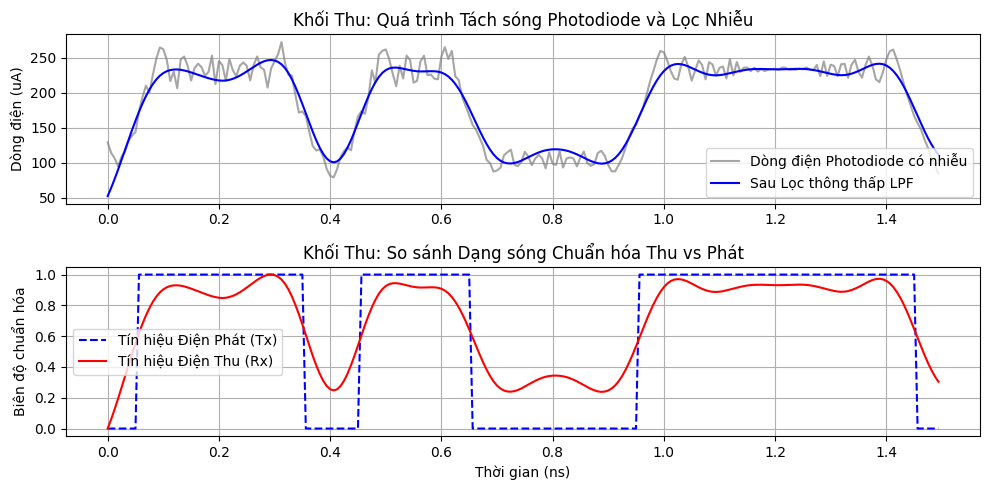


--------------------------------------------------
4. ĐÁNH GIÁ EYE DIAGRAM & BER
--------------------------------------------------


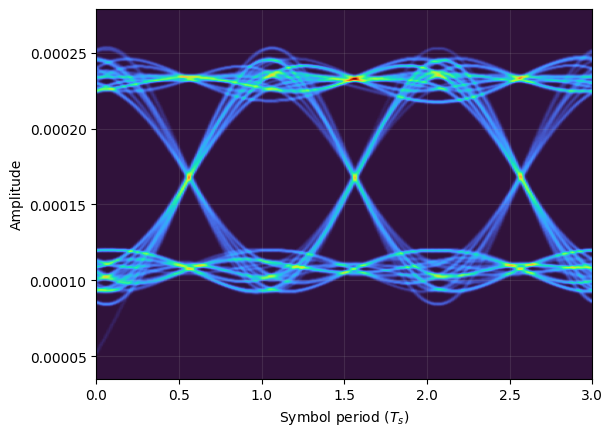

-----Thông số Eye diagram-----
• Dòng trung bình bit 1 (I1) = 0.00023470
• Dòng trung bình bit 0 (I0) = 0.00010329
• Độ lệch chuẩn bit 1 (σ1) = 0.00000861
• Độ lệch chuẩn bit 0 (σ0) = 0.00000853
• Ngưỡng quyết định tối ưu (Id) = 0.00016865
• FACTOR Q = 7.66694467 

----------THÔNG SỐ BER----------
• Tổng bit lỗi đếm được = 0
• BER = 0.00000000e+00
• Pb = 8.80708572e-15


In [20]:
# QUÁ TRÌNH XỬ LÝ KHỐI THU 
from math import erfc

# 1. Tách sóng quang thành Dòng điện (Photodiode PIN)
Ip = param.R * P_rx_optical

# 2. Thêm 2 loại nhiễu vật lý tại phía thu
sigma2_shot = 2 * e * np.mean(Ip) * param.B
noise_shot = np.random.normal(0, np.sqrt(sigma2_shot), N_samples)

sigma2_thermal = (4 * k * T_temp / R_load) * param.B
noise_thermal = np.random.normal(0, np.sqrt(sigma2_thermal), N_samples)

I_rx_noisy = Ip + noise_shot + noise_thermal

# 3. Bộ lọc thông thấp LPF loại bỏ nhiễu cao tần
h_lpf = lowPassFIR(fc=0.75*param.Rs, fs=param.Fs, N=64)
I_filt = firFilter(h_lpf, I_rx_noisy)

# TÍNH TOÁN SỐ LIỆU KHỐI THU
SNR_rx = 10 * np.log10(np.var(Ip) / (sigma2_shot + sigma2_thermal))
print("\n--------------------------------------------------")
print("3. KẾT QUẢ SỐ LIỆU KHỐI THU & NHIỄU (RECEIVER & NOISE)")
print("--------------------------------------------------")
print(f"• Dòng quang điện trung bình (I_dc):         {np.mean(Ip)*1e6:.2f} uA")
print(f"• Độ lệch chuẩn Nhiễu hạt (Shot noise):      {np.sqrt(sigma2_shot)*1e6:.4f} uA")
print(f"• Độ lệch chuẩn Nhiễu nhiệt (Thermal noise):  {np.sqrt(sigma2_thermal)*1e6:.4f} uA")
print(f"• Tỷ số Tín hiệu trên Nhiễu điện (SNR_el):   {SNR_rx:.2f} dB")

# VẼ ĐỒ THỊ KHỐI THU (DẠNG SÓNG)
fig, ax = plt.subplots(2, 1, figsize=(10, 5))
ax[0].plot(t_ns, I_rx_noisy[:N_simulate]*1e6, color='gray', alpha=0.7, label='Dòng điện Photodiode có nhiễu')
ax[0].plot(t_ns, I_filt[:N_simulate]*1e6, color='blue', linewidth=1.5, label='Sau Lọc thông thấp LPF')
ax[0].set_title("Khối Thu: Quá trình Tách sóng Photodiode và Lọc Nhiễu")
ax[0].set_ylabel("Dòng điện (uA)")
ax[0].legend()
ax[0].grid(True)

sigTx_norm = (sigTx_elec[:N_simulate] - np.min(sigTx_elec[:N_simulate])) / np.ptp(sigTx_elec[:N_simulate])
I_filt_norm = (I_filt[:N_simulate] - np.min(I_filt[:N_simulate])) / np.ptp(I_filt[:N_simulate])
ax[1].plot(t_ns, sigTx_norm, label='Tín hiệu Điện Phát (Tx)', linestyle='--', color='blue')
ax[1].plot(t_ns, I_filt_norm, label='Tín hiệu Điện Thu (Rx)', color='red')
ax[1].set_title("Khối Thu: So sánh Dạng sóng Chuẩn hóa Thu vs Phát")
ax[1].set_xlabel("Thời gian (ns)")
ax[1].set_ylabel("Biên độ chuẩn hóa")
ax[1].legend()
ax[1].grid(True)
plt.tight_layout()
plt.show()

#ĐÁNH GIÁ KẾT QUẢ ĐỒ ÁN: BIỂU ĐỒ MẮT & KHẢO SÁT BER
print("\n--------------------------------------------------")
print("4. ĐÁNH GIÁ EYE DIAGRAM & BER")
print("--------------------------------------------------")

#Vẽ mắt với toàn bộ dữ liệu thu được
eyediagram(
    I_filt, 
    Nsamples=len(I_filt), 
    SpS=param.SpS, 
    n=3, 
    ptype="fancy", 
    cmap="turbo"
)
plt.show()
# Trích xuất mẫu tại tâm ký hiệu
I_Rx = I_filt[0::param.SpS]
I1 = np.mean(I_Rx[bitsTx==1])
I0 = np.mean(I_Rx[bitsTx==0])
σ1 = np.std(I_Rx[bitsTx==1])
σ0 = np.std(I_Rx[bitsTx==0])
Id = (σ1*I0 + σ0*I1)/(σ1 + σ0)
Q  = (I1-I0)/(σ1 + σ0)

print('-----Thông số Eye diagram-----')
print('• Dòng trung bình bit 1 (I1) = %.8f'%(I1))
print('• Dòng trung bình bit 0 (I0) = %.8f'%(I0))
print('• Độ lệch chuẩn bit 1 (σ1) = %.8f'%(σ1))
print('• Độ lệch chuẩn bit 0 (σ0) = %.8f'%(σ0))
print('• Ngưỡng quyết định tối ưu (Id) = %.8f'%(Id))
print('• FACTOR Q = %.8f \n'%(Q))

# Áp dụng quy tắc quyết định
bitsRx = np.empty(bitsTx.size)
bitsRx[I_Rx > Id] = 1
bitsRx[I_Rx <= Id] = 0

err = np.logical_xor(bitsRx, bitsTx)
BER = np.mean(err)
Pb = 0.5*erfc(Q/np.sqrt(2))

print('----------THÔNG SỐ BER----------')
print('• Tổng bit lỗi đếm được = %d'%(err.sum()))
print('• BER = %.8e'%(BER))
print('• Pb = %.8e'%(Pb))


--------------------------------------------------
5. KHẢO SÁT TỶ LỆ LỖI BIT (BER) THEO CỰ LY SỢI QUANG
--------------------------------------------------


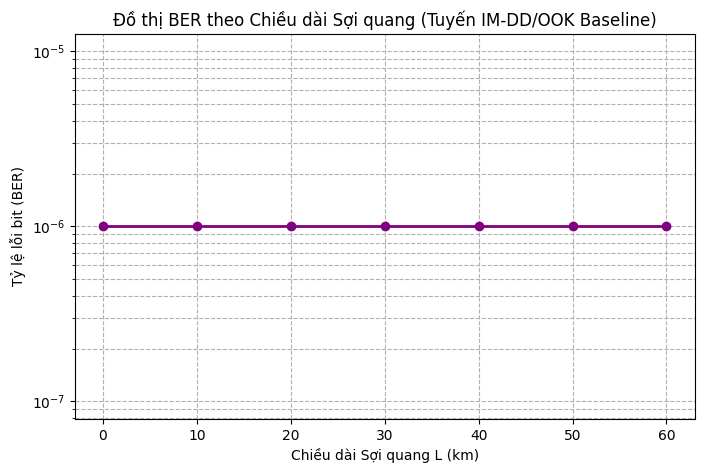

In [21]:
# Khảo sát BER theo các cự ly sợi quang L 
print("\n--------------------------------------------------")
print("5. KHẢO SÁT TỶ LỆ LỖI BIT (BER) THEO CỰ LY SỢI QUANG")
print("--------------------------------------------------")
L_vec = np.linspace(0, 60, 7)
BER_list = []

for L_i in L_vec:
    H_fiber_i = np.exp(-alpha_m * (L_i * 1e3) / 2) * np.exp(1j * (beta2 / 2) * (omega**2) * (L_i * 1e3))
    E_rx_i = np.fft.ifft(np.fft.fft(E_tx) * H_fiber_i)
    
    I_dc_i = param.R * np.abs(E_rx_i)**2
    n_shot_i = np.random.normal(0, np.sqrt(2 * e * np.mean(I_dc_i) * param.B), N_samples)
    n_therm_i = np.random.normal(0, np.sqrt((4 * k * T_temp / R_load) * param.B), N_samples)
    
    I_filt_i = firFilter(h_lpf, I_dc_i + n_shot_i + n_therm_i)
    
    I_sampled = I_filt_i[0 :: param.SpS][:len(bitsTx)]
    threshold = (np.max(I_sampled) + np.min(I_sampled)) / 2
    bitsRx = (I_sampled > threshold).astype(int)
    
    ber = min(np.mean(bitsTx != bitsRx), np.mean(bitsTx != (1 - bitsRx)))
    BER_list.append(max(ber, 1e-6))

# Vẽ đồ thị BER
plt.figure(figsize=(8, 5))
plt.semilogy(L_vec, BER_list, 'o-', color='purple', linewidth=2, markersize=6)
plt.xlabel('Chiều dài Sợi quang L (km)')
plt.ylabel('Tỷ lệ lỗi bit (BER)')
plt.title('Đồ thị BER theo Chiều dài Sợi quang (Tuyến IM-DD/OOK Baseline)')
plt.grid(True, which="both", ls="--")
plt.show()